Develop a robust data ingestion and validation workflow to import TSLA stock data, performing comprehensive inspection and validation of column types and identification of missing values across the dataset.

In [3]:
!pip install yfinance 


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
ticker = "TSLA"

data = yf.download(
    ticker,
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

print("TSLA data downloaded successfully!")
print("Dataset shape:", data.shape)

data.head()

TSLA data downloaded successfully!
Dataset shape: (1254, 5)


Price,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,
2021-11-05,407.363342,413.290009,402.666656,409.333344,64886400
2021-11-08,387.646667,399.000000,377.666656,383.263336,100337100
2021-11-09,341.166656,391.500000,337.173340,391.200012,177317400
2021-11-10,355.983337,359.366669,329.103333,336.803345,128408100
2021-11-11,354.503326,368.323334,351.559998,367.589996,67189800


In [6]:
# Handle possible multi-level columns from Yahoo Finance
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data.columns = data.columns.str.lower()

data.head()

Price,close,high,low,open,volume
Date,,,,,
2021-11-05,407.363342,413.290009,402.666656,409.333344,64886400
2021-11-08,387.646667,399.000000,377.666656,383.263336,100337100
2021-11-09,341.166656,391.500000,337.173340,391.200012,177317400
2021-11-10,355.983337,359.366669,329.103333,336.803345,128408100
2021-11-11,354.503326,368.323334,351.559998,367.589996,67189800


In [7]:
print("Dataset Information:")
print(data.info())

print("\nDataset Shape:")
print(data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nFirst 5 Records:")
display(data.head())

print("\nLast 5 Records:")
display(data.tail())

Dataset Information:
<class 'pandas.DataFrame'>
DatetimeIndex: 1254 entries, 2021-11-05 to 2026-11-04
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   close   1254 non-null   float64
 1   high    1254 non-null   float64
 2   low     1254 non-null   float64
 3   open    1254 non-null   float64
 4   volume  1254 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 58.8 KB
None

Dataset Shape:
(1254, 5)

Column Names:
['close', 'high', 'low', 'open', 'volume']

First 5 Records:


Price,close,high,low,open,volume
Date,,,,,
2021-11-05,407.363342,413.290009,402.666656,409.333344,64886400
2021-11-08,387.646667,399.000000,377.666656,383.263336,100337100
2021-11-09,341.166656,391.500000,337.173340,391.200012,177317400
2021-11-10,355.983337,359.366669,329.103333,336.803345,128408100
2021-11-11,354.503326,368.323334,351.559998,367.589996,67189800



Last 5 Records:


Price,close,high,low,open,volume
Date,,,,,
2026-10-29,403.299988,406.980011,400.500000,405.630005,22858300
2026-10-30,399.809998,404.220001,387.519989,393.220001,41737200
2026-11-02,403.820007,414.230011,397.609985,404.660004,43141100
2026-11-03,398.500000,406.500000,396.529999,406.250000,26647700
2026-11-04,385.190002,392.040009,375.500000,379.799988,47673700


In [8]:
dtype_report = pd.DataFrame({
    "Column": data.columns,
    "Data Type": data.dtypes.astype(str).values,
    "Non-Null Values": data.notnull().sum().values
})

display(dtype_report)

,Column,Data Type,Non-Null Values
0,close,float64,1254
1,high,float64,1254
2,low,float64,1254
3,open,float64,1254
4,volume,int64,1254


In [9]:
expected_numeric = [
    "open", "high", "low", "close", "volume"
]

for col in expected_numeric:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

print("Data type validation completed.")

display(data.dtypes)

Data type validation completed.


Price
close     float64
high      float64
low       float64
open      float64
volume      int64
dtype: object

In [10]:
missing_values = pd.DataFrame({
    "Missing Count": data.isnull().sum(),
    "Missing Percentage": (
        data.isnull().mean() * 100
    ).round(2)
})

display(missing_values)

,Missing Count,Missing Percentage
Price,,
close,0,0.0
high,0,0.0
low,0,0.0
open,0,0.0
volume,0,0.0


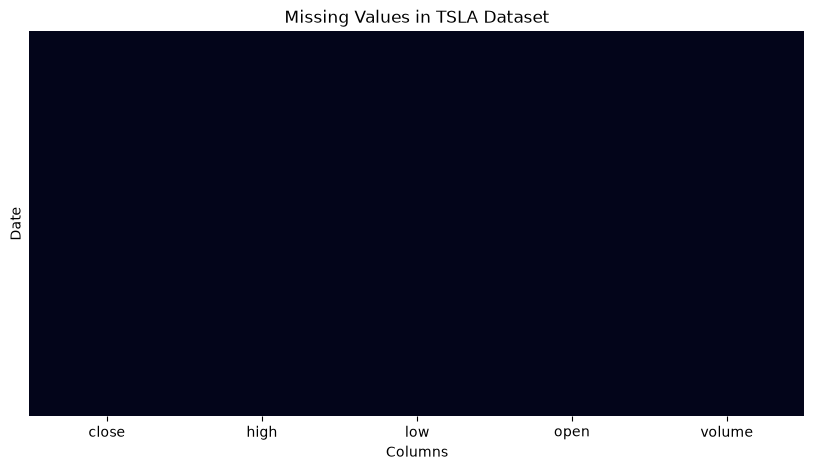

In [11]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    data.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in TSLA Dataset")
plt.xlabel("Columns")
plt.show()

In [12]:
print("Duplicate rows:", data.duplicated().sum())

print("Duplicate dates:", data.index.duplicated().sum())

Duplicate rows: 0
Duplicate dates: 0


In [13]:
required_columns = [
    "open", "high", "low", "close", "volume"
]

missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if missing_columns:
    print("Missing required columns:", missing_columns)
else:
    print("All required columns are available.")

    print("\nInvalid negative prices:")
    print((data[["open", "high", "low", "close"]] < 0).sum())

    print("\nNegative volume values:")
    print((data["volume"] < 0).sum())

    print("\nInvalid OHLC relationships:")
    invalid_ohlc = (
        (data["high"] < data[["open", "close", "low"]].max(axis=1)) |
        (data["low"] > data[["open", "close"]].min(axis=1))
    )

    print("Invalid records:", invalid_ohlc.sum())

All required columns are available.

Invalid negative prices:
Price
open     0
high     0
low      0
close    0
dtype: int64

Negative volume values:
0

Invalid OHLC relationships:
Invalid records: 0


In [15]:
clean_data = data.copy()

# Remove duplicate dates
clean_data = clean_data[
    ~clean_data.index.duplicated(keep="first")
]

# Remove rows with missing required values
clean_data = clean_data.dropna(
    subset=required_columns
)

print("Original shape:", data.shape)
print("Cleaned shape:", clean_data.shape)

print("Remaining missing values:")
print(clean_data.isnull().sum())

Original shape: (1254, 5)
Cleaned shape: (1254, 5)
Remaining missing values:
Price
close     0
high      0
low       0
open      0
volume    0
dtype: int64


In [16]:
validation_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Missing Values",
        "Duplicate Rows",
        "Duplicate Dates",
        "Remaining Missing Values"
    ],
    "Result": [
        len(clean_data),
        len(clean_data.columns),
        int(data.isnull().sum().sum()),
        int(data.duplicated().sum()),
        int(data.index.duplicated().sum()),
        int(clean_data.isnull().sum().sum())
    ]
})

display(validation_report)

,Metric,Result
0,Total Rows,1254
1,Total Columns,5
2,Missing Values,0
3,Duplicate Rows,0
4,Duplicate Dates,0
5,Remaining Missing Values,0



# TSLA Stock Data Ingestion and Validation

## Objectives
- Import Tesla (TSLA) historical stock data.
- Inspect dataset structure and column names.
- Validate numerical data types.
- Identify missing values and duplicates.
- Check stock price and volume consistency.
- Clean and save the validated dataset.

## Methodology
1. Downloaded historical TSLA stock data using Yahoo Finance.
2. Inspected dataset dimensions and column information.
3. Checked and converted numerical columns.
4. Identified missing values and duplicate records.
5. Validated stock prices and volume values.
6. Removed duplicate dates and incomplete required records.
7. Exported the cleaned dataset as a CSV file.

## Conclusion
The TSLA stock data ingestion and validation workflow was implemented using Python and Pandas. The dataset was inspected for data types, missing values, duplicate records, and invalid stock values. The cleaned dataset was exported for further exploratory data analysis and stock market analysis.
